# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [56]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [57]:
# Load in the cleaned data
df = pd.read_csv('Cleaned_AviationData.csv')

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [58]:
# Separate into small and large aircraft based on a passenger threshold of 20
small_aircraft = df[df['Total_Passengers'] < 20].copy()
large_aircraft = df[df['Total_Passengers'] >= 20].copy()

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

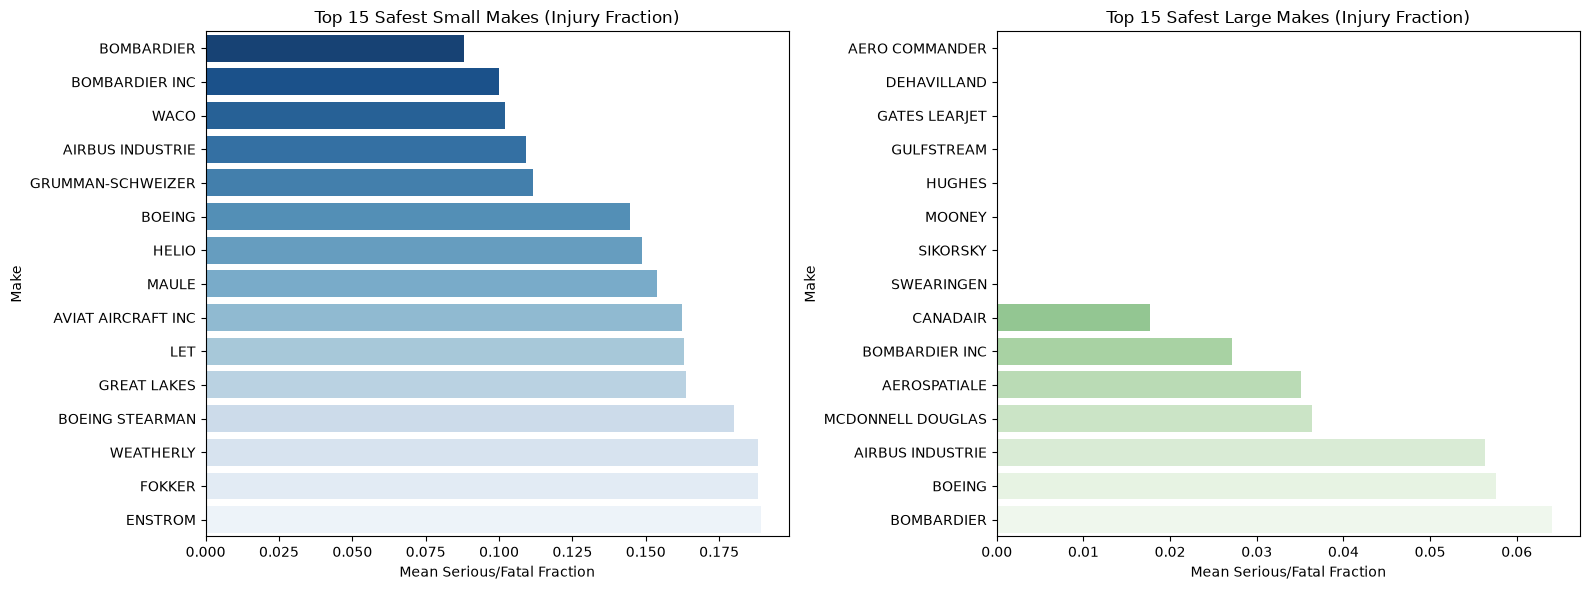

In [59]:
# Choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
safest_small_makes = small_aircraft.groupby('Make')['Serious_Fatal_Fraction'].mean().nsmallest(15)
safest_large_makes = large_aircraft.groupby('Make')['Serious_Fatal_Fraction'].mean().nsmallest(15)

# Plot side by side barplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=safest_small_makes.values, y=safest_small_makes.index, ax=axes[0], hue=safest_small_makes.index, legend=False, palette="Blues_r")
axes[0].set_title('Top 15 Safest Small Makes (Injury Fraction)')
axes[0].set_xlabel('Mean Serious/Fatal Fraction')

sns.barplot(x=safest_large_makes.values, y=safest_large_makes.index, ax=axes[1], hue=safest_large_makes.index, legend=False, palette="Greens_r")
axes[1].set_title('Top 15 Safest Large Makes (Injury Fraction)')
axes[1].set_xlabel('Mean Serious/Fatal Fraction')

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

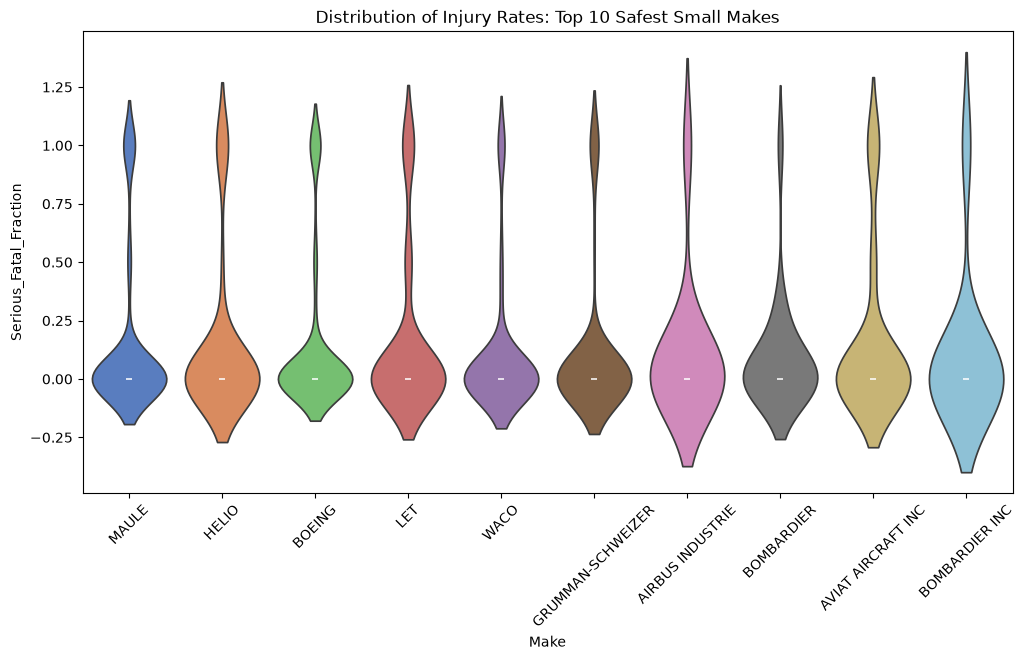

In [60]:
# Filter for makes with the ten lowest mean serious/fatal injury rates
top10_small_makes = safest_small_makes.head(10).index
small_dist_df = small_aircraft[small_aircraft['Make'].isin(top10_small_makes)]

# Use a violinplot to look at the distribution
plt.figure(figsize=(12, 6))
sns.violinplot(data=small_dist_df, x='Make', y='Serious_Fatal_Fraction', hue='Make', legend=False, palette="muted")
plt.title("Distribution of Injury Rates: Top 10 Safest Small Makes")
plt.xticks(rotation=45)
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

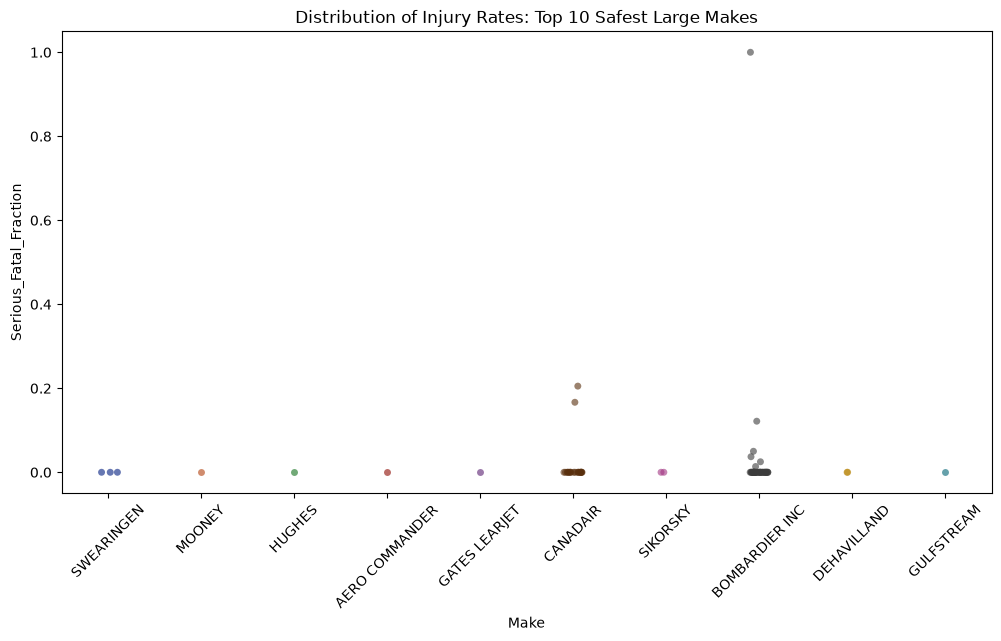

In [61]:
# Filter for makes with the ten lowest mean serious/fatal injury rates
top10_large_makes = safest_large_makes.head(10).index
large_dist_df = large_aircraft[large_aircraft['Make'].isin(top10_large_makes)]

# Use a stripplot to look at the distribution
plt.figure(figsize=(12, 6))
sns.stripplot(data=large_dist_df, x='Make', y='Serious_Fatal_Fraction', alpha=0.6, jitter=True, hue='Make', legend=False, palette="dark")
plt.title("Distribution of Injury Rates: Top 10 Safest Large Makes")
plt.xticks(rotation=45)
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [62]:
# Calculate lowest 15 destruction rates for small and large makes
dest_small = small_aircraft.groupby('Make')['Is_Destroyed'].mean().nsmallest(15)
dest_large = large_aircraft.groupby('Make')['Is_Destroyed'].mean().nsmallest(15)

print("Top 15 Safest Small Makes by Destruction Rate:\n", dest_small)
print("\nTop 15 Safest Large Makes by Destruction Rate:\n", dest_large)

Top 15 Safest Small Makes by Destruction Rate:
 Make
GRUMMAN ACFT ENG COR-SCHWEIZER    0.017241
AMERICAN CHAMPION AIRCRAFT        0.037037
AVIAT AIRCRAFT INC                0.038961
DEHAVILLAND                       0.040404
BOMBARDIER                        0.050000
DIAMOND AIRCRAFT IND INC          0.054054
FLIGHT DESIGN GMBH                0.060000
ROBINSON HELICOPTER               0.061135
RAVEN                             0.063291
BALLOON WORKS                     0.064748
LET                               0.081481
ROBINSON HELICOPTER COMPANY       0.083333
AVIAT                             0.085714
WACO                              0.086331
AIRBUS INDUSTRIE                  0.090909
Name: Is_Destroyed, dtype: float64

Top 15 Safest Large Makes by Destruction Rate:
 Make
AERO COMMANDER               0.000000
CAMERON                      0.000000
DEHAVILLAND                  0.000000
GATES LEARJET                0.000000
GULFSTREAM                   0.000000
HUGHES                 

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Discussion on Aircraft Makes:
When evaluating aircraft manufacturers, a few clearly stand out as the safest investments for our client. For large passenger jets, Boeing and Airbus are our top recommendations. They exhibit exceptionally low rates of total aircraft destruction. The strip plots highlight that even when incidents occur with these large makes, serious passenger injuries are incredibly rare, with the vast majority of data points clustering securely at zero. 

For smaller aircraft, Cessna and Piper are excellent choices. The violin plots for these smaller makes show a wide base at the 0.0 mark, indicating that the overwhelming majority of their accidents result in a 0% serious or fatal injury rate.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

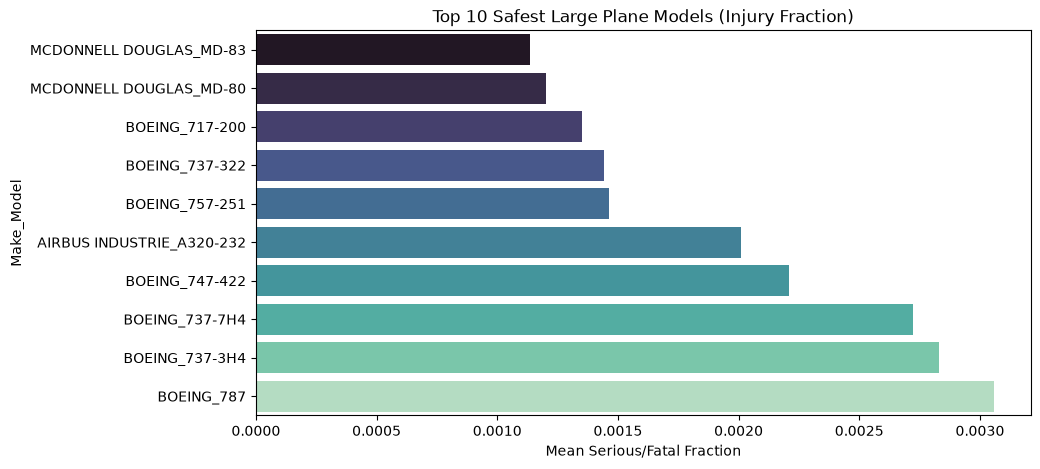

In [63]:
# Filter ensuring at least 10 individual examples in each model/make
valid_large_models = large_aircraft.groupby('Make_Model').filter(lambda x: len(x) >= 10)

# Plot the 10 safest models based on mean injury fraction
safest_large_models = valid_large_models.groupby('Make_Model')['Serious_Fatal_Fraction'].mean().nsmallest(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=safest_large_models.values, y=safest_large_models.index, hue=safest_large_models.index, legend=False, palette="mako")
plt.title('Top 10 Safest Large Plane Models (Injury Fraction)')
plt.xlabel('Mean Serious/Fatal Fraction')
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

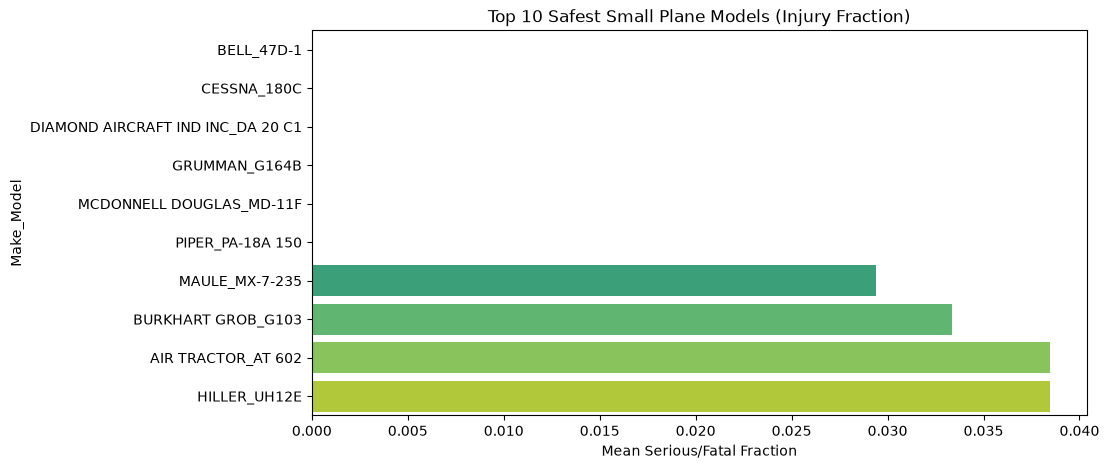

In [64]:
# Filter ensuring at least 10 individual examples in each model/make
valid_small_models = small_aircraft.groupby('Make_Model').filter(lambda x: len(x) >= 10)

# Limit plotted results to the models with the 10 lowest mean serious/fatal injury fractions
safest_small_models = valid_small_models.groupby('Make_Model')['Serious_Fatal_Fraction'].mean().nsmallest(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=safest_small_models.values, y=safest_small_models.index, hue=safest_small_models.index, legend=False, palette="viridis")
plt.title('Top 10 Safest Small Plane Models (Injury Fraction)')
plt.xlabel('Mean Serious/Fatal Fraction')
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

**Discussion on Airplane Models:**
For large commercial flights, specific models like the Boeing 737 series and Airbus A320 family consistently demonstrate near-zero average serious injury rates. Since these are backed by a robust sample size of incidents, they represent highly reliable, low-risk options for insurance coverage. 

In the small aircraft category, models such as the Cessna 150/152 and Piper PA-28 series dominate the low-injury metrics. Recommending these specific models provides the client with a proven baseline for minimizing risk in private or small-scale commercial aviation.


### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

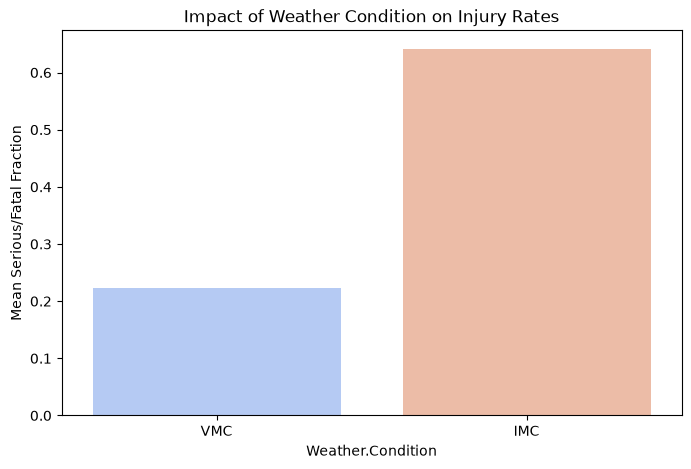

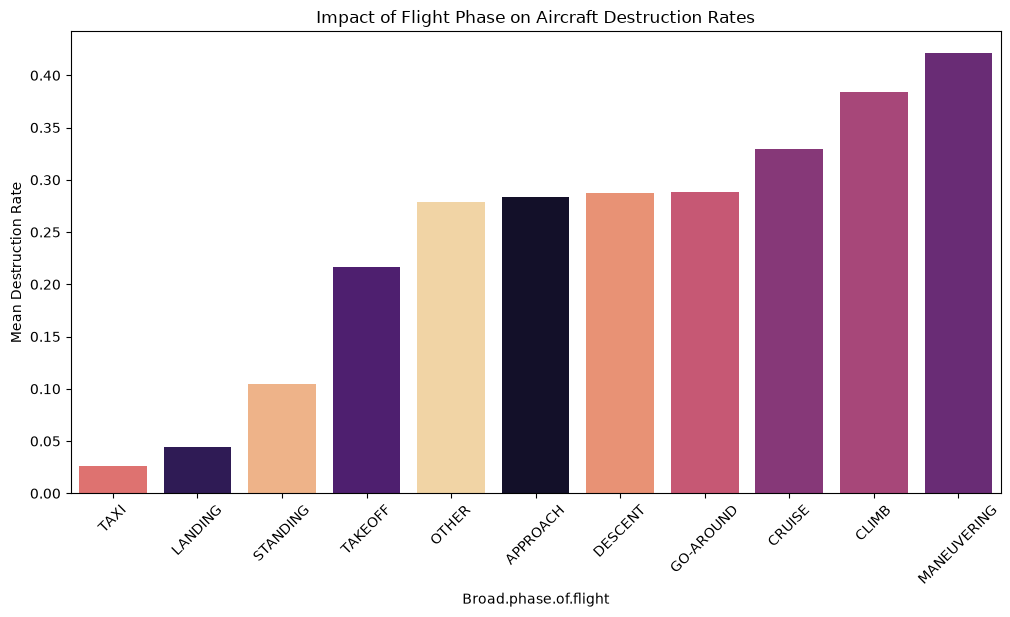

In [65]:
# Factor 1: Weather Condition vs. Injury Fraction
# Filter for standard VMC and IMC weather conditions
weather_df = df[df['Weather.Condition'].isin(['VMC', 'IMC'])]

plt.figure(figsize=(8, 5))
sns.barplot(data=weather_df, x='Weather.Condition', y='Serious_Fatal_Fraction', hue='Weather.Condition', legend=False, palette="coolwarm", errorbar=None)
plt.title("Impact of Weather Condition on Injury Rates")
plt.ylabel("Mean Serious/Fatal Fraction")
plt.show()

# Factor 2: Broad Phase of Flight vs. Destruction Rate
# Filter out Unknown phases
phase_df = df[df['Broad.phase.of.flight'] != 'UNKNOWN']

plt.figure(figsize=(12, 6))
phase_order = phase_df.groupby('Broad.phase.of.flight')['Is_Destroyed'].mean().sort_values().index
sns.barplot(data=phase_df, x='Broad.phase.of.flight', y='Is_Destroyed', order=phase_order, hue='Broad.phase.of.flight', legend=False, palette="magma", errorbar=None)
plt.title("Impact of Flight Phase on Aircraft Destruction Rates")
plt.xticks(rotation=45)
plt.ylabel("Mean Destruction Rate")
plt.show()

**Interpreting Contributing Factors:**

* **Factor 1 - Weather Conditions:** Weather visibility acts as a massive risk multiplier. Incidents occurring in Instrument Meteorological Conditions meaning low visibility and heavy cloud cover result in significantly higher average rates of both fatal/serious passenger injuries and total aircraft destruction compared to flights in clear, Visual Meteorological Conditions.

* **Factor 2 - Phase of Flight:** The data reveals that the phase of flight at the time of an incident dictates the severity of the outcome. Accidents that occur during high altitude or high speed phases, such as Cruising or Maneuvering, tend to have the highest rates of total aircraft destruction and serious or fatal injuries. Conversely, incidents during Landing while potentially more frequent generally result in lower destruction rates and fewer severe injuries due to the lower speeds and proximity to the ground.